In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

In [3]:
from scipy.stats import spearmanr, kendalltau

In [4]:
#dat_new = pd.read_csv('/Users/ravirajan/Projects/TTD/TTD_Raw-20260328.csv', low_memory=False).replace(' ', None)
#dat_new = dat_new[dat_new.Week_Start_Date >= "2026-02-16"]

In [78]:
#dat_all = pd.read_csv('/Users/ravirajan/Projects/TTD/TTD_Raw-20260328.csv', low_memory=False).replace(' ', None)
#dat_all['week_start'] = dat_all.Week_Start_Date.apply(lambda x: x.split(" ")[0])

In [5]:
dat = pd.read_csv('/Users/ravirajan/Projects/TTD/TTD_Raw-20260328.csv', low_memory=False).replace(' ', None)

In [6]:
dat = dat[dat.Week_Start_Date < "2026-02-16"]

In [7]:
#['News and Politics', 'Food & Drink', 'Style & Fashion',
#       'Business and Finance', 'Technology & Computing', 'All',
#       'Events and Attractions', 'Travel', 'Personal Finance',
#       'Automotive', 'Shopping', 'Home & Garden', 'Pets',
#       'Healthy Living', 'Medical Health']

adv_cats = dat.Advertiser_Category.unique()
adv_cats

array(['News and Politics', 'Food & Drink', 'Style & Fashion',
       'Business and Finance', 'Technology & Computing', 'All',
       'Events and Attractions', 'Travel', 'Personal Finance',
       'Automotive', 'Shopping', 'Home & Garden', 'Pets',
       'Healthy Living', 'Medical Health'], dtype=object)

In [8]:
def get_geo(litems):
    check = ['Asia', 'US', 'Global', 'APAC']
    for c in check:
        if c in litems:
            return c
    return 'Unknown'

In [9]:
dat['geo'] = dat.Full_Path.apply(lambda x: get_geo(x.replace(" ", "").split(">")))

In [10]:
dat.groupby('geo').size()

geo
APAC         3060
Asia       311970
Global     807075
US         212025
Unknown    133620
dtype: int64

In [11]:
dat['Clean_Path'] = dat.Full_Path.apply(lambda x: x.lower().replace(" ", ""))

In [12]:
def get_seg_2(x):
    val = x.replace("otp>", "").split(">")[1] if len(x.split(">")) > 1 else "N/A"
    return val

In [13]:
dat['segment_last'] = dat.Clean_Path.apply(lambda x: x.split(">")[-1].replace("age", ""))
dat['segment_1'] = dat.Clean_Path.apply(lambda x: x.split(">")[0])
##dat['segment_2'] = dat.Clean_Path.apply(lambda x: x.split(">")[1] if len(x.split(">")) > 1 else "N/A")
dat['segment_2'] = dat.Clean_Path.apply(lambda x: x.replace("otp>", "").split(">")[1] if len(x.split(">")) > 1 else "N/A")
dat['week_start'] = dat.Week_Start_Date.apply(lambda x: x.split(" ")[0])

In [14]:
seg_last_vb = pd.DataFrame(dat[dat.Third_Party_Data_Provider_Id == 'sharethis']['segment_last'].value_counts())
seg_last_da = pd.DataFrame(dat[dat.Third_Party_Data_Provider_Id == 'dav2shreths']['segment_last'].value_counts())

In [15]:
def find_common_substrings(list1, list2, fuzzy_only=True):
    """
    Finds all strings from list1 that are substrings of any string in list2.
    """
    common_subs = set()
    matches = []
    exact_matches = set()
    for s1 in list1:
        for s2 in list2:
            if s1 == s2:
                exact_matches.add(s1)
                if fuzzy_only:
                    continue
            if len(s1) > 2 and s1.lower() in s2.lower():
                common_subs.add(s1.lower())
                matches.append([s1, s2])
            elif len(s2) > 2 and s2.lower() in s1.lower():
                common_subs.add(s2.lower())
                matches.append([s1, s2])
    return list(common_subs), matches, exact_matches

In [16]:
seg_common, matches, exact_matches = find_common_substrings(seg_last_vb[seg_last_vb["count"] > 1].index, 
                                             seg_last_da[seg_last_da["count"] > 1].index)
len(seg_common)

509

In [17]:
dat.head()

,Active_ID_Count,Active_ID_Count_Percentile,Advertiser_Category,Avg_Relevance,Avg_Relevance_Percentile,Avg_Value_Percentile,Avg_Value_Score,Data_Cost,Effective_Impression_Count,Full_Path,...,Third_Party_Data_Provider_Element_Id,Third_Party_Data_Provider_Id,Third_Party_Data_Sub_Provider_Id,Week_Start_Date,geo,Clean_Path,segment_last,segment_1,segment_2,week_start
0,NaN,NaN,News and Politics,2.7,54.8,NaN,NaN,NaN,NaN,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>motorc...,aprilia,dataalliance,automotive,2025-10-20
1,NaN,NaN,Food & Drink,3.3,67.4,NaN,NaN,NaN,NaN,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>autos>...,model3,dataalliance,automotive,2025-10-20
2,NaN,NaN,Style & Fashion,3.8,85.3,NaN,NaN,NaN,NaN,Data Alliance > CPG > Interest > Global > Food...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>cpg>interest>global>food&beverage...,frozen,dataalliance,cpg,2025-10-20
3,341886000.0,99.4,Food & Drink,3.8,75.5,98.4,68.0,0.11,24168.0,Data Alliance > Retail > Interest > Global > M...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,"dataalliance>retail>interest>global>movies,mus...",books,dataalliance,retail,2025-10-20
4,NaN,NaN,Business and Finance,3.9,77.4,NaN,NaN,NaN,NaN,Data Alliance > Automotive > Interest > Global...,...,NaN,dav2shreths,None,2025-10-20 00:00:00+00,Global,dataalliance>automotive>interest>global>autos>...,xc40,dataalliance,automotive,2025-10-20


In [18]:
dat.columns

Index(['Active_ID_Count', 'Active_ID_Count_Percentile', 'Advertiser_Category',
       'Avg_Relevance', 'Avg_Relevance_Percentile', 'Avg_Value_Percentile',
       'Avg_Value_Score', 'Data_Cost', 'Effective_Impression_Count',
       'Full_Path', 'Match_Pct', 'Match_Pct_Percentile', 'Paid_Pct',
       'Paid_Pct_Percentile', 'Received_ID_Count', 'Selected_Pct',
       'Selected_Pct_Percentile', 'Third_Party_Data_Provider_Element_Id',
       'Third_Party_Data_Provider_Id', 'Third_Party_Data_Sub_Provider_Id',
       'Week_Start_Date', 'geo', 'Clean_Path', 'segment_last', 'segment_1',
       'segment_2', 'week_start'],
      dtype='object')

# clean dataset

In [19]:
dat1 = dat[dat.Received_ID_Count.isna() == False] 
dat1.shape

(216553, 27)

In [20]:
dat1['Received_ID_Count'] = dat1['Received_ID_Count'].astype(int)
dat1['Active_ID_Count'] = dat1['Active_ID_Count'].astype(int)
dat1['Effective_Impression_Count'] = dat1['Effective_Impression_Count'].astype(int)

/var/folders/wt/bzrqdlb17zv7h4r1y9jqpg_w0000gp/T/ipykernel_29849/1306883678.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat1['Received_ID_Count'] = dat1['Received_ID_Count'].astype(int)
/var/folders/wt/bzrqdlb17zv7h4r1y9jqpg_w0000gp/T/ipykernel_29849/1306883678.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat1['Active_ID_Count'] = dat1['Active_ID_Count'].astype(int)
/var/folders/wt/bzrqdlb17zv7h4r1y9jqpg_w0000gp/T/ipykernel_29849/1306883678.py:3: SettingWithCopyWarning: 
A value is trying to 

In [21]:
dat['Data_Cost'] = dat['Data_Cost'].astype(float)
dat1['Match_Pct'] = dat1['Match_Pct'].astype(float)
dat1['Match_Pct_Percentile'] = dat1['Match_Pct_Percentile'].astype(float)

/var/folders/wt/bzrqdlb17zv7h4r1y9jqpg_w0000gp/T/ipykernel_29849/816265128.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat1['Match_Pct'] = dat1['Match_Pct'].astype(float)
/var/folders/wt/bzrqdlb17zv7h4r1y9jqpg_w0000gp/T/ipykernel_29849/816265128.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dat1['Match_Pct_Percentile'] = dat1['Match_Pct_Percentile'].astype(float)


## filter out bad rows

In [22]:
dat2 = dat1[dat1.Received_ID_Count > 0]

# Model

In [23]:
#seg_col = 'segment_last'
seg_col = 'segment_2'
##seg_col = 'Full_Path'

In [24]:
#x_c_cols = [seg_col, 'week_start', 'Third_Party_Data_Provider_Id', 'geo', 'segment_2'] # Advertiser_Category
x_c_cols = ['segment_last', 'week_start', 'Third_Party_Data_Provider_Id', 'geo', 'segment_2']
#x_c_cols = [seg_col, 'week_start', 'Third_Party_Data_Provider_Id', 'geo',] # Advertiser_Category
x_n_cols = ['Received_ID_Count'] #[ 'Active_ID_Count_Percentile', 'Avg_Relevance_Percentile', 'Paid_Pct_Percentile']
# 'Avg_Value_Percentile' has NAs

In [25]:
Xn = pd.DataFrame(dat2[x_n_cols], dtype=float)
Xn['log_Received_ID_Count'] = Xn['Received_ID_Count'].apply(lambda x: np.log(x))

from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
Xn = pd.DataFrame(sc.fit_transform(Xn), columns=Xn.columns, index=Xn.index)

In [26]:
from sklearn.linear_model import Ridge

def build_models(dat3, x_c_cols, Xn, x1='Avg_Relevance', x2='Data_Cost'):
    output = {}
    models = {}
    #
    Xc = pd.get_dummies(dat3[x_c_cols])
    X = Xn.join(Xc, how='inner')
    yr = dat3[x1]
    yd = dat3[x2].astype(float)
    #
    mod_r = Ridge(alpha=0.000001, fit_intercept=True)
    mod_r.fit(X, yr)
    models['relevance'] = mod_r
    output['relevance'] = {}
    output['relevance']['R2'] = mod_r.score(X, yr)
    #
    mod_d = Ridge(alpha=0.000001)
    mod_d.fit(X, yd)
    models['revenue'] = mod_d
    output['revenue'] = {}
    output['revenue']['R2'] = mod_d.score(X, yd)
    #
    coef_r = pd.DataFrame(mod_r.coef_, index=X.columns, columns=['beta'])
    coef_d = pd.DataFrame(mod_d.coef_, index=X.columns, columns=['beta'])
    coef_rd = coef_r.join(coef_d, lsuffix='_rel', rsuffix='_rev')
    #
    return output, models, coef_rd

In [27]:
def get_corr(coefs, kind='pearson', dbg=False):
    if kind == 'spearmanr':
        if dbg: print ("spearmanr")
        val = spearmanr(coef_seg['beta_rel'].values, coef_seg['beta_rev'].values)
        rel_rev_corr = val.statistic
    elif kind == 'kendalltau':
        if dbg: print ("kendalltau")
        val = kendalltau(coef_seg['beta_rel'].values, coef_seg['beta_rev'].values)
        rel_rev_corr = val.statistic
    else:
        if dbg: print ("pearson")
        rel_rev_corr = coef_seg.corr().loc['beta_rel']['beta_rev']
    return rel_rev_corr

In [28]:
seg_col

'segment_2'

<Axes: >

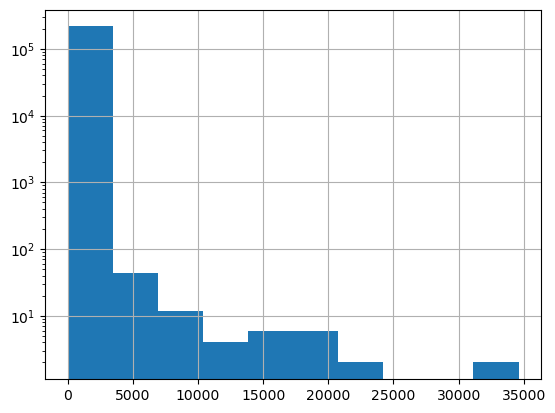

In [29]:
dat2['Data_Cost'].hist(log=True)

In [30]:
dat2_ind = dat2[dat2.Advertiser_Category != 'All']

In [31]:
dat2_ind['Data_Cost'].quantile(0.37)

0.0

In [32]:
dat2_ind['Data_Cost'].describe()

count    149341.000000
mean          7.025343
std         186.084207
min           0.000000
25%           0.000000
50%           0.020000
75%           0.410000
max       34596.240000
Name: Data_Cost, dtype: float64

### loop through adv_cat

In [35]:
top_n = 10

In [36]:
my_metrics = {}
coefs = {}
models = {}
rel_list = []
rev_list = []
for adv_cat in adv_cats:
    dat3 = dat2[dat2.Advertiser_Category == adv_cat]
    dat3 = dat3[dat3['Data_Cost'] > 0] # extra
    outputs, model_adv, coef_rd = build_models(dat3, x_c_cols, Xn)
    coef_seg = coef_rd.filter(regex=seg_col, axis='index')
    my_metrics[adv_cat] = outputs
    my_metrics[adv_cat]['rel_rev_rho'] = get_corr(coef_seg)
    my_metrics[adv_cat]['rel_rev_spr'] = get_corr(coef_seg, kind='spearmanr')
    my_metrics[adv_cat]['rel_rev_kdt'] = get_corr(coef_seg, kind='kendalltau')
    my_metrics[adv_cat]['data_cost'] = dat3['Data_Cost'].sum()
    my_metrics[adv_cat]['avg_rel'] = dat3['Avg_Relevance'].mean()
    my_metrics[adv_cat]['n'] = dat3.shape[0]
    coefs[adv_cat] = coef_rd
    models[adv_cat] = model_adv
    rel_list.append([adv_cat] + list(coef_seg.sort_values('beta_rel', ascending=False).index.values[:top_n]))
    rev_list.append([adv_cat] + list(coef_seg.sort_values('beta_rev', ascending=False).index.values[:top_n]))

# nz -> non_zero rev
my_metrics_nz = dict(my_metrics)
coefs_nz = dict(coefs)
models_nz = dict(models)

In [37]:
my_metrics = {}
coefs = {}
models = {}
rel_list_1 = []
rev_list_1 = []
for adv_cat in adv_cats:
    dat3 = dat2[dat2.Advertiser_Category == adv_cat]
    dat3 = dat3[dat3['Data_Cost'] > 0] # extra
    outputs, model_adv, coef_rd = build_models(dat3, x_c_cols, Xn, x1="Avg_Relevance_Percentile")
    coef_seg = coef_rd.filter(regex=seg_col, axis='index')
    my_metrics[adv_cat] = outputs
    my_metrics[adv_cat]['rel_rev_rho'] = get_corr(coef_seg)
    my_metrics[adv_cat]['rel_rev_spr'] = get_corr(coef_seg, kind='spearmanr')
    my_metrics[adv_cat]['rel_rev_kdt'] = get_corr(coef_seg, kind='kendalltau')
    my_metrics[adv_cat]['data_cost'] = dat3['Data_Cost'].sum()
    my_metrics[adv_cat]['avg_rel'] = dat3['Avg_Relevance'].mean()
    my_metrics[adv_cat]['n'] = dat3.shape[0]
    coefs[adv_cat] = coef_rd
    models[adv_cat] = model_adv
    rel_list_1.append([adv_cat] + list(coef_seg.sort_values('beta_rel', ascending=False).index.values[:top_n]))
    rev_list_1.append([adv_cat] + list(coef_seg.sort_values('beta_rev', ascending=False).index.values[:top_n]))

# nz -> non_zero rev
my_metrics_perc = dict(my_metrics)
coefs_perc = dict(coefs)
models_perc = dict(models)

In [113]:
#coef_seg.reset_index().apply(lambda x: get_seg_2(x[0]), axis=1)

In [38]:
met_nz = pd.DataFrame(my_metrics_nz).T
for k in ['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt', 'data_cost', 'avg_rel', 'n']:
    met_nz[k] = met_nz[k].astype(float)
met_nz

,relevance,revenue,rel_rev_rho,rel_rev_spr,rel_rev_kdt,data_cost,avg_rel,n
News and Politics,{'R2': 0.9119101994574761},{'R2': 0.5150244590289548},0.691617,0.744591,0.577236,6202.66,6.719073,1898.0
Food & Drink,{'R2': 0.9541253911318429},{'R2': 0.38185521406183265},-0.026211,-0.147705,-0.096774,51272.06,4.334420,7301.0
Style & Fashion,{'R2': 0.7482769439235767},{'R2': 0.5513298205803394},0.312281,0.259957,0.195960,28586.91,3.832038,5094.0
Business and Finance,{'R2': 0.9434495804919069},{'R2': 0.8148943033287821},0.036496,0.080074,0.059608,184494.41,4.747330,16313.0
Technology & Computing,{'R2': 0.934017451916388},{'R2': 0.2836768737364401},0.015011,0.090831,0.081967,241417.68,4.015985,7438.0
All,{'R2': 0.934848643923281},{'R2': 0.33257745634344416},0.323458,0.478202,0.340082,1101537.86,4.641106,48691.0
Events and Attractions,{'R2': 0.9077022983836676},{'R2': 0.26788561216852813},0.027555,-0.055778,-0.014278,21081.84,4.454848,6002.0
Travel,{'R2': 0.7773420458263627},{'R2': 0.48485089541779425},0.268419,0.308089,0.196664,71618.34,4.170963,9357.0
Personal Finance,{'R2': 0.9122696148397077},{'R2': 0.5441579830731447},0.563663,0.517020,0.368831,30603.26,4.614102,4744.0
Automotive,{'R2': 0.9530577623224017},{'R2': 0.4885580887275738},0.167931,-0.046791,-0.033898,208889.84,5.338087,8961.0


In [39]:
met_perc = pd.DataFrame(my_metrics_perc).T
for k in ['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt', 'data_cost', 'avg_rel', 'n']:
    met_perc[k] = met_perc[k].astype(float)
met_perc

,relevance,revenue,rel_rev_rho,rel_rev_spr,rel_rev_kdt,data_cost,avg_rel,n
News and Politics,{'R2': 0.9510629356077316},{'R2': 0.5150244590289548},0.703286,0.618832,0.481998,6202.66,6.719073,1898.0
Food & Drink,{'R2': 0.9735851969640296},{'R2': 0.38185521406183265},0.020524,-0.101286,-0.069124,51272.06,4.334420,7301.0
Style & Fashion,{'R2': 0.8078406911876789},{'R2': 0.5513298205803394},0.348066,0.310462,0.228283,28586.91,3.832038,5094.0
Business and Finance,{'R2': 0.9518803029568178},{'R2': 0.8148943033287821},0.112848,0.224643,0.160311,184494.41,4.747330,16313.0
Technology & Computing,{'R2': 0.941082699994907},{'R2': 0.2836768737364401},0.448114,0.456070,0.327340,241417.68,4.015985,7438.0
All,{'R2': 0.9647030018794637},{'R2': 0.33257745634344416},0.277647,0.504354,0.356498,1101537.86,4.641106,48691.0
Events and Attractions,{'R2': 0.935784620923741},{'R2': 0.26788561216852813},-0.144027,-0.110070,-0.069276,21081.84,4.454848,6002.0
Travel,{'R2': 0.7697355954151808},{'R2': 0.48485089541779425},0.319087,0.377181,0.245830,71618.34,4.170963,9357.0
Personal Finance,{'R2': 0.9293252668351507},{'R2': 0.5441579830731447},0.534147,0.479904,0.342857,30603.26,4.614102,4744.0
Automotive,{'R2': 0.9582711828035919},{'R2': 0.4885580887275738},0.239035,-0.070964,-0.057627,208889.84,5.338087,8961.0


array([[<Axes: title={'center': 'rel_rev_rho'}>,
        <Axes: title={'center': 'rel_rev_spr'}>,
        <Axes: title={'center': 'rel_rev_kdt'}>]], dtype=object)

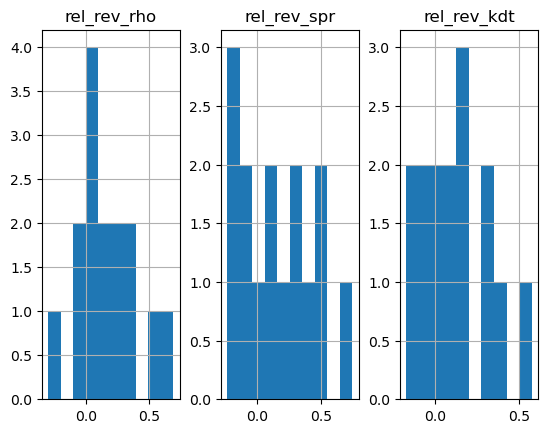

In [40]:
met_nz[['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt']].hist(layout=(1,3))

array([[<Axes: title={'center': 'rel_rev_rho'}>,
        <Axes: title={'center': 'rel_rev_spr'}>,
        <Axes: title={'center': 'rel_rev_kdt'}>]], dtype=object)

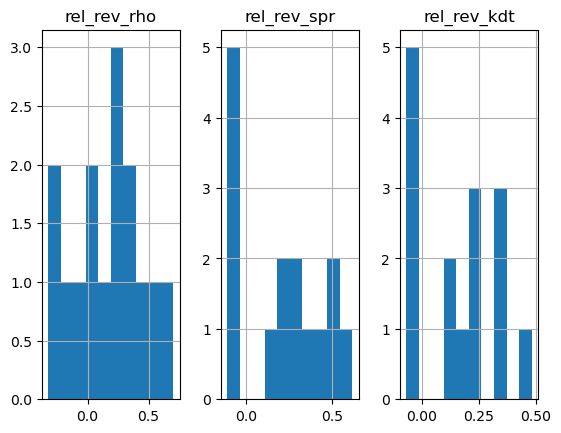

In [41]:
met_perc[['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt']].hist(layout=(1,3))

In [46]:
rev_list = [[item.replace("segment_2_", "") for item in sublist] for sublist in rev_list]
rel_list = [[item.replace("segment_2_", "") for item in sublist] for sublist in rel_list]
rel_list_1 = [[item.replace("segment_2_", "") for item in sublist] for sublist in rel_list_1]

In [47]:
pd.DataFrame(rev_list).T.to_csv('/Users/ravirajan/Projects/TTD/TTD_rev_top_seg2.csv')

In [48]:
pd.DataFrame(rel_list).T.to_csv('/Users/ravirajan/Projects/TTD/TTD_rel_top_seg2.csv')

In [49]:
pd.DataFrame(rel_list_1).T.to_csv('/Users/ravirajan/Projects/TTD/TTD_relp_top_seg2.csv')

In [121]:
met_nz[['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt']].join(
    met_perc[['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt']], rsuffix="_perc")

,rel_rev_rho,rel_rev_spr,rel_rev_kdt,rel_rev_rho_perc,rel_rev_spr_perc,rel_rev_kdt_perc
News and Politics,0.691617,0.744591,0.577236,0.703286,0.618832,0.481998
Food & Drink,-0.026211,-0.147705,-0.096774,0.020524,-0.101286,-0.069124
Style & Fashion,0.312281,0.259957,0.195960,0.348066,0.310462,0.228283
Business and Finance,0.036496,0.080074,0.059608,0.112848,0.224643,0.160311
Technology & Computing,0.015011,0.090831,0.081967,0.448114,0.456070,0.327340
All,0.323458,0.478202,0.340082,0.277647,0.504354,0.356498
Events and Attractions,0.027555,-0.055778,-0.014278,-0.144027,-0.110070,-0.069276
Travel,0.268419,0.308089,0.196664,0.319087,0.377181,0.245830
Personal Finance,0.563663,0.517020,0.368831,0.534147,0.479904,0.342857
Automotive,0.167931,-0.046791,-0.033898,0.239035,-0.070964,-0.057627


In [122]:
met_nz[['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt']].join(
    met_perc[['rel_rev_rho', 'rel_rev_spr', 'rel_rev_kdt']], rsuffix="_perc").describe()

,rel_rev_rho,rel_rev_spr,rel_rev_kdt,rel_rev_rho_perc,rel_rev_spr_perc,rel_rev_kdt_perc
count,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
mean,0.160928,0.159744,0.119057,0.171080,0.208814,0.153846
std,0.250185,0.288058,0.209728,0.287860,0.251878,0.182107
min,-0.297944,-0.232565,-0.175141,-0.322700,-0.110070,-0.069276
25%,0.021283,-0.051284,-0.025692,-0.013784,-0.075660,-0.049153
50%,0.100599,0.090831,0.081967,0.239035,0.224643,0.160311
75%,0.290350,0.366071,0.243354,0.333577,0.416625,0.286585
max,0.691617,0.744591,0.577236,0.703286,0.618832,0.481998


<Axes: xlabel='advertiser category', ylabel='correlation between relevance and revenue'>

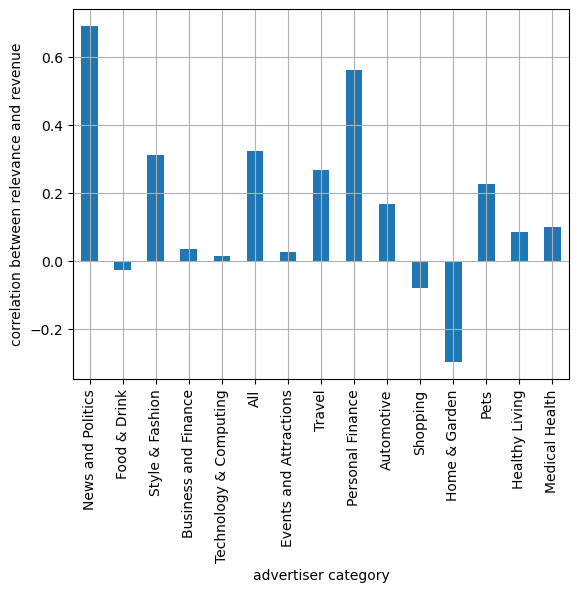

In [123]:
met_nz['rel_rev_rho'].plot(kind='bar', grid=True, 
                           xlabel="advertiser category", ylabel="correlation between relevance and revenue")

<Axes: xlabel='advertiser category', ylabel='correlation between relevance percentile and revenue'>

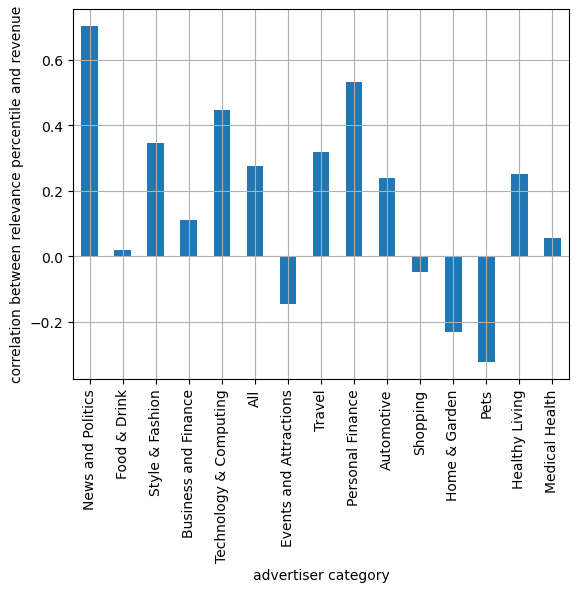

In [124]:
met_perc['rel_rev_rho'].plot(kind='bar', grid=True, 
                           xlabel="advertiser category", ylabel="correlation between relevance percentile and revenue")

<Axes: xlabel='advertiser category', ylabel='correlation between relevance and revenue'>

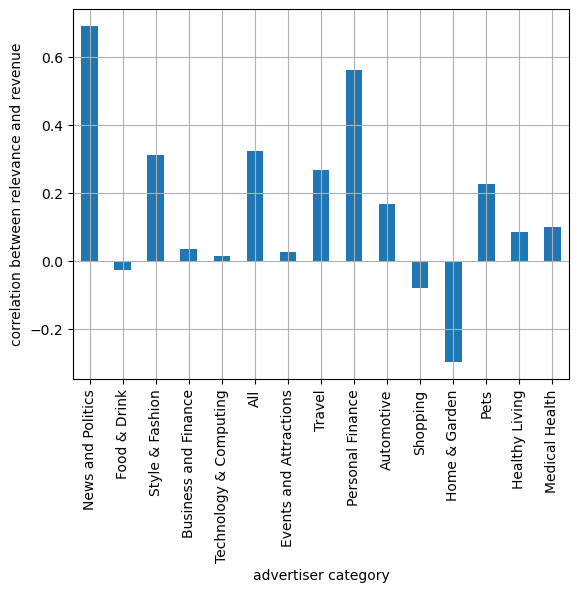

In [126]:
met_nz['rel_rev_rho'].plot(kind='bar', grid=True, xlabel="advertiser category", ylabel="correlation between relevance and revenue")

In [ ]:
#coefs_nz['Pets'].filter(regex=seg_col, axis='index').sort_values('beta_rel', ascending=False).head(20)

In [ ]:
#coefs_raw['Pets'].filter(regex=seg_col, axis='index').sort_values('beta_rel', ascending=False).head(20)

<Axes: xlabel='advertiser category', ylabel='correlation between relevance and revenue'>

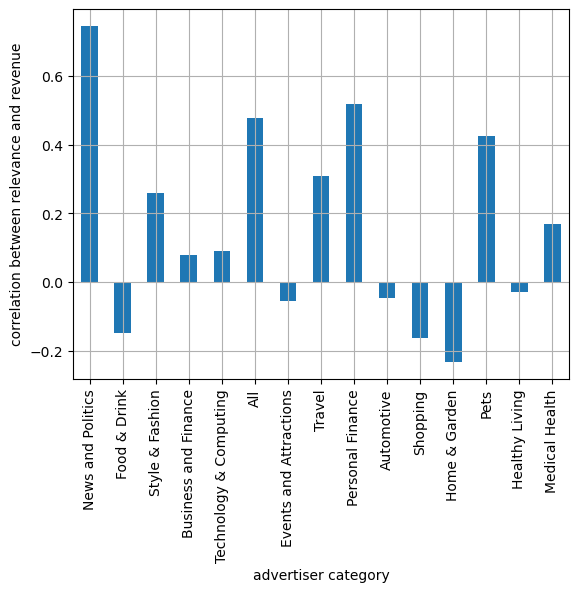

In [127]:
met_nz['rel_rev_spr'].plot(kind='bar', grid=True, xlabel="advertiser category", ylabel="correlation between relevance and revenue")

coef_seg.plot(kind='scatter', x='beta_rel', y='beta_rev', logy=True, title='correlation between revenue and relevance')

## alternate approach

In [ ]:
dat2.head()

In [ ]:
corr2 = {}
for k, v in dat2.groupby('Clean_Path'):
    cur = v[['Avg_Relevance', 'Data_Cost']].diff().dropna()
    if cur.shape[0] > 1:
        corr2[k] = cur.corr().iloc[0, 1]
corr2_df = pd.DataFrame([corr2]).T

In [ ]:
corr3 = {}
for k, v in dat2.groupby('Clean_Path'):
    cur = v[['Avg_Relevance_Percentile', 'Data_Cost']].diff().dropna()
    if cur.shape[0] > 1:
        corr3[k] = cur.corr().iloc[0, 1]

corr3_df = pd.DataFrame([corr3]).T

In [ ]:
corr3_df.describe()

In [ ]:
corr2_df.describe()

In [ ]:
corr2_df.hist()

In [ ]:
corr3_df.hist()

## compare with age

In [128]:
age = pd.read_csv('/Users/ravirajan/Projects/TTD/TTD_Relevance_Age.csv', low_memory=False).replace(' ', None)

In [129]:
age.head()

,st_id,ttd_name,Advertiser_Category,BT,DA,updated_at,age,min_rel,avg_rel,max_rel,...,max_rel_ptile,min_sel,avg_sel,max_sel,min_sel_ptile,avg_sel_ptile,max_sel_ptile,min_rev,avg_rev,max_rev
0,3f0cfefc,B2B > Industry > Publishing,Business and Finance,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,2.9,10.183333,27.3,...,62.375000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3f0cfefc,B2B > Industry > Publishing,Home & Garden,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,2.9,10.233333,30.6,...,65.841667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3f0cfefc,B2B > Industry > Publishing,Personal Finance,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,3.5,9.758333,27.5,...,71.550000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3f0cfefc,B2B > Industry > Publishing,Pets,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,2.7,40.075000,222.8,...,60.733333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3f0cfefc,B2B > Industry > Publishing,Shopping,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,3.0,29.725000,109.4,...,61.725000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [131]:
age['segment_2'] = age['ttd_name'].apply(lambda x: get_seg_2(x))

In [132]:
age.head()

,st_id,ttd_name,Advertiser_Category,BT,DA,updated_at,age,min_rel,avg_rel,max_rel,...,min_sel,avg_sel,max_sel,min_sel_ptile,avg_sel_ptile,max_sel_ptile,min_rev,avg_rev,max_rev,segment_2
0,3f0cfefc,B2B > Industry > Publishing,Business and Finance,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,2.9,10.183333,27.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Industry
1,3f0cfefc,B2B > Industry > Publishing,Home & Garden,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,2.9,10.233333,30.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Industry
2,3f0cfefc,B2B > Industry > Publishing,Personal Finance,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,3.5,9.758333,27.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Industry
3,3f0cfefc,B2B > Industry > Publishing,Pets,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,2.7,40.075000,222.8,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Industry
4,3f0cfefc,B2B > Industry > Publishing,Shopping,1.0,0.0,2020-08-18T15:04:13.392Z,5.69589,3.0,29.725000,109.4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Industry


<Axes: xlabel='age', ylabel='avg_rel_ptile'>

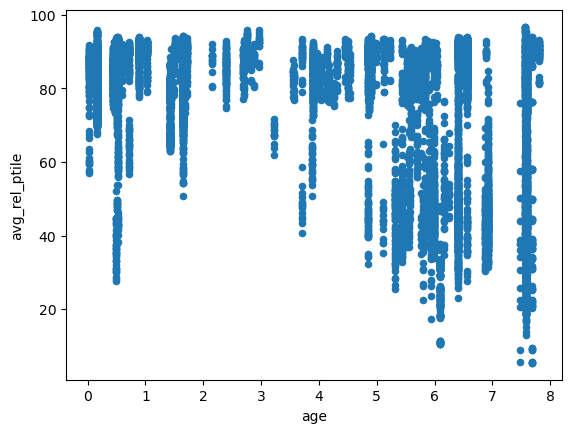

In [145]:
age.plot(kind='scatter', x='age', y='avg_rel_ptile')

<Axes: xlabel='age', ylabel='avg_rev'>

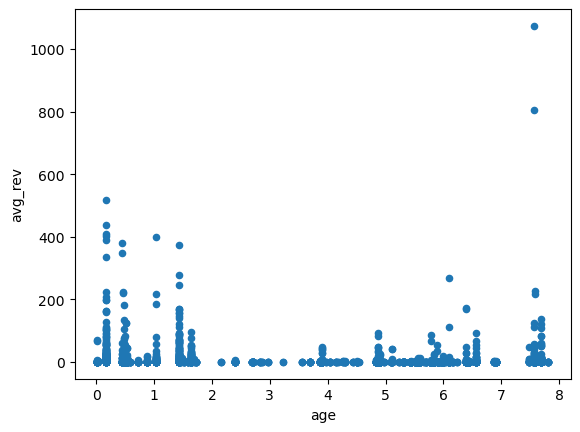

In [146]:
age.plot(kind='scatter', x='age', y='avg_rev')

In [133]:
age.groupby(['Advertiser_Category', 'segment_2'])[['age', 'avg_rel_ptile']].describe()

age                                \
                                          count      mean       std       min   
Advertiser_Category segment_2                                                   
All                 APAC                    6.0  7.647489  0.085005  7.473973   
                    Apparel Shoppers        1.0  7.589041       NaN  7.589041   
                    Arts & Entertainment    1.0  7.572603       NaN  7.572603   
                    Arts & Entertainment   90.0  4.023349  2.958401  0.438356   
                    Auto Buyers            17.0  0.505399  0.017249  0.484932   
...                                         ...       ...       ...       ...   
Travel              science                16.0  2.755308  3.462213  0.169863   
                    shopping               30.0  1.588402  2.830288  0.169863   
                    sports                 28.0  1.988160  3.191900  0.169863   
                    travel                  1.0  0.169863       NaN  0.169863   
                    travel                 20.0  1.112740  2.187955  0.169863   

                                                                         \
                                                25%       50%       75%   
Advertiser_Category segment_2                                             
All                 APAC                   7.682192  7.682192  7.682192   
                    Apparel Shoppers       7.589041  7.589041  7.589041   
                    Arts & Entertainment   7.572603  7.572603  7.572603   
                    Arts & Entertainment   1.643836  1.643836  7.572603   
                    Auto Buyers            0.490411  0.501370  0.526027   
...                                             ...       ...       ...   
Travel              science                0.169863  0.169863  6.556164   
                    shopping               0.169863  0.169863  0.488356   
                    sports                 0.169863  0.169863  1.928082   
                    travel                 0.169863  0.169863  0.169863   
                    travel                 0.169863  0.169863  0.469178   

                                                    avg_rel_ptile             \
                                                max         count       mean   
Advertiser_Category segment_2                                                  
All                 APAC                   7.682192           6.0  38.794444   
                    Apparel Shoppers       7.589041           1.0  83.850000   
                    Arts & Entertainment   7.572603           1.0  33.258333   
                    Arts & Entertainment   7.572603          90.0  69.891667   
                    Auto Buyers            0.526027          17.0  82.683333   
...                                             ...           ...        ...   
Travel              science                7.572603          16.0  77.722396   
                    shopping               7.572603          30.0  77.436389   
                    sports                 7.572603          28.0  78.386012   
                    travel                 0.169863           1.0  72.925000   
                    travel                 7.572603          20.0  78.843333   

                                                                            \
                                                 std        min        25%   
Advertiser_Category segment_2                                                
All                 APAC                    0.114827  38.683333  38.712500   
                    Apparel Shoppers             NaN  83.850000  83.850000   
                    Arts & Entertainment         NaN  33.258333  33.258333   
                    Arts & Entertainment   22.109128  26.425000  46.922917   
                    Auto Buyers            19.300796  30.958333  86.541667   
...                                              ...        ...        ...   
Travel              science        

In [134]:
age.groupby(['Advertiser_Category', 'segment_2'])[['age', 'avg_rel_ptile']].median()

age  avg_rel_ptile
Advertiser_Category segment_2                                     
All                 APAC                   7.682192      38.750000
                    Apparel Shoppers       7.589041      83.850000
                    Arts & Entertainment   7.572603      33.258333
                    Arts & Entertainment   1.643836      84.425000
                    Auto Buyers            0.501370      90.441667
...                                             ...            ...
Travel              science                0.169863      78.545833
                    shopping               0.169863      77.787500
                    sports                 0.169863      78.341667
                    travel                 0.169863      72.925000
                    travel                 0.169863      78.258333

[1725 rows x 2 columns]

In [141]:
age.groupby(['Advertiser_Category', 'segment_2'])[['age']].median().pivot_table(
    index='Advertiser_Category', columns='segment_2', values='age').T.to_csv('/Users/ravirajan/Projects/TTD/TTD_age_seg2.csv')

In [143]:
age.groupby(['Advertiser_Category', 'segment_2'])[['avg_rel_ptile']].median().pivot_table(
    index='Advertiser_Category', columns='segment_2', values='avg_rel_ptile').T.to_csv('/Users/ravirajan/Projects/TTD/TTD_relptile_seg2.csv')